## 1. Импортировать датасет для бинарной классификации

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve, ConfusionMatrixDisplay
)
from sklearn.preprocessing import StandardScaler
import os

import kagglehub

path = kagglehub.dataset_download("prekshad2166/healthy-meal-plan-dataset")
file = os.path.join(path,"healthy_meal_plans.csv")

Using Colab cache for faster access to the 'healthy-meal-plan-dataset' dataset.


In [ ]:
df = pd.read_csv(file)

df.head()

,meal_name,num_ingredients,calories,prep_time,protein,fat,carbs,vegan,vegetarian,keto,paleo,gluten_free,mediterranean,is_healthy
0,Gluten-Free Pasta,0.272727,0.490909,0.84,0.783679,0.597907,0.444572,0,0,0,0,1,0,1
1,Grilled Salmon,0.909091,0.158182,0.70,0.143588,0.652082,0.050609,0,0,1,1,1,1,0
2,Lentil Soup,0.454545,0.700000,0.40,0.620637,0.612748,0.000688,0,1,0,0,0,0,0
3,Chickpea Stew,0.909091,0.105455,0.82,0.046893,0.975761,0.229026,1,1,0,0,0,0,0
4,Turkey Lettuce Wraps,0.181818,0.441818,0.04,0.864340,0.681575,0.449293,0,0,1,1,1,1,0


## 2. Очистить датасет от пропусков и выбросов, если они есть, выполнить нормализацию либо стандартизацию данных, если необходимо.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   meal_name        500 non-null    object 
 1   num_ingredients  500 non-null    float64
 2   calories         500 non-null    float64
 3   prep_time        500 non-null    float64
 4   protein          500 non-null    float64
 5   fat              500 non-null    float64
 6   carbs            500 non-null    float64
 7   vegan            500 non-null    int64  
 8   vegetarian       500 non-null    int64  
 9   keto             500 non-null    int64  
 10  paleo            500 non-null    int64  
 11  gluten_free      500 non-null    int64  
 12  mediterranean    500 non-null    int64  
 13  is_healthy       500 non-null    int64  
dtypes: float64(6), int64(7), object(1)
memory usage: 54.8+ KB


In [ ]:
df.describe()

,num_ingredients,calories,prep_time,protein,fat,carbs,vegan,vegetarian,keto,paleo,gluten_free,mediterranean,is_healthy
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,0.489818,0.504149,0.486480,0.505704,0.506822,0.507081,0.334000,0.574000,0.366000,0.388000,0.528000,0.302000,0.094000
std,0.305054,0.290267,0.293234,0.291046,0.282906,0.292257,0.472112,0.494989,0.482192,0.487783,0.499715,0.459585,0.292121
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.272727,0.231818,0.220000,0.236392,0.257945,0.251489,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.454545,0.509091,0.490000,0.521935,0.516733,0.510196,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000
75%,0.727273,0.751364,0.740000,0.764155,0.751306,0.746904,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


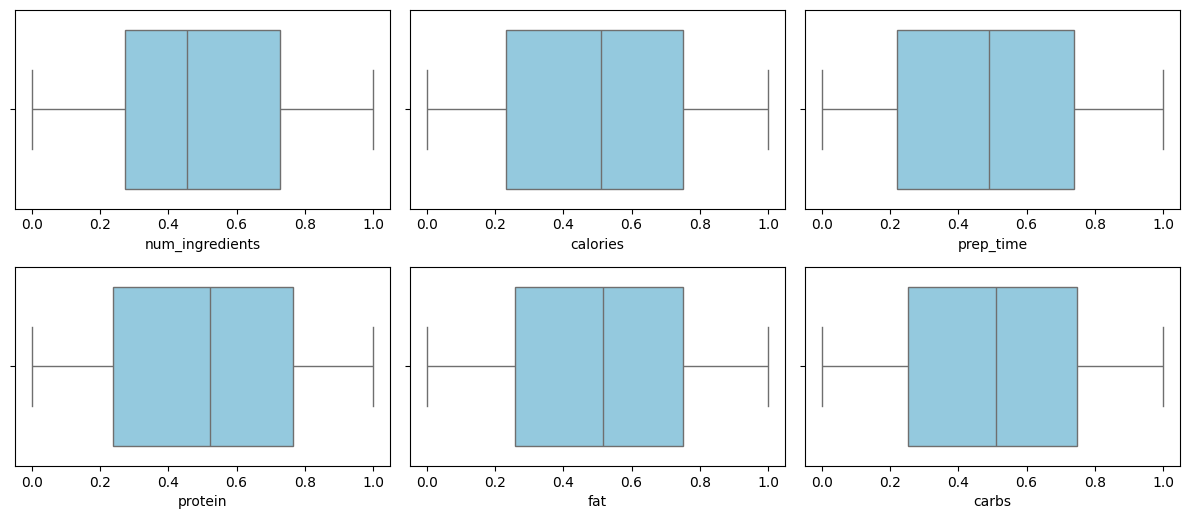

In [ ]:
df_num_features = df.select_dtypes(include=['float64'])
plt.figure(figsize=(12, 10))
for i, col in enumerate(df_num_features):
    plt.subplot(4, 3, i + 1)
    sns.boxplot(x=df[col], color='skyblue')

plt.tight_layout()
plt.show()

Данные нормализованы, пропусков и выбросов нет.

## 3. Выбрать целевую переменную и сформировать набор признаков.

In [ ]:
num_cols = df.select_dtypes(include=['float64', 'int64']).columns.drop('is_healthy')

features = [col for col in num_cols]
target = ['is_healthy']

X = df[features].values
y = df['is_healthy'].values

print(f"Признаки: {features}")
print(f"X: {X.shape}, y: {y.shape}")

Признаки: ['num_ingredients', 'calories', 'prep_time', 'protein', 'fat', 'carbs', 'vegan', 'vegetarian', 'keto', 'paleo', 'gluten_free', 'mediterranean']
X: (500, 12), y: (500,)


In [ ]:
df[target].value_counts()

,count
is_healthy,
0,453
1,47


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y,  shuffle=True
)

print(f"Обучающая выборка: {X_train.shape[0]}")
print(f"Тестовая выборка:  {X_test.shape[0]}")

Обучающая выборка: 400
Тестовая выборка:  100


## 4. Создать модель бинарной классификации на основе моделей логистической регрессии, SVM, CART. Оценить качество моделей.

### 4.1 Логистическая регрессия

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
lr = LogisticRegression(max_iter=1000, random_state=42,class_weight='balanced')
lr.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
lr.coef_, lr.intercept_

(array([[-0.14574556, -0.097559  ,  0.12939873,  0.35534468, -0.96740056,
         -0.57397142, -0.24529268, -0.18755558,  0.04570695, -0.08502251,
         -0.28296036, -0.46432551]]),
 array([-0.5109599]))

In [ ]:
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

In [ ]:
y_pred_lr

array([1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1])

In [ ]:
y_prob_lr

array([0.57375564, 0.69626999, 0.73098466, 0.30361004, 0.24340559,
       0.29421597, 0.82886325, 0.09171736, 0.58448345, 0.40712   ,
       0.08453531, 0.10887801, 0.47103193, 0.72936422, 0.29259668,
       0.68101483, 0.79636578, 0.85994762, 0.02809062, 0.2109825 ,
       0.14173831, 0.73241233, 0.51730514, 0.18651824, 0.79630371,
       0.83632401, 0.26020677, 0.84043023, 0.53384173, 0.26238284,
       0.25883074, 0.05182327, 0.21562896, 0.59344975, 0.15891547,
       0.30566724, 0.34367142, 0.17426274, 0.06234299, 0.93854276,
       0.38963541, 0.33215676, 0.29924339, 0.6048787 , 0.24752962,
       0.2749676 , 0.50320459, 0.57583447, 0.32687611, 0.07727063,
       0.53525571, 0.38267658, 0.88740869, 0.47890258, 0.08789483,
       0.78593416, 0.25331057, 0.14911525, 0.20314897, 0.56713153,
       0.15778965, 0.37941786, 0.33585557, 0.24207599, 0.59613653,
       0.83112276, 0.04674211, 0.4999651 , 0.22715632, 0.70434126,
       0.30090239, 0.29165753, 0.52656243, 0.28164987, 0.07818

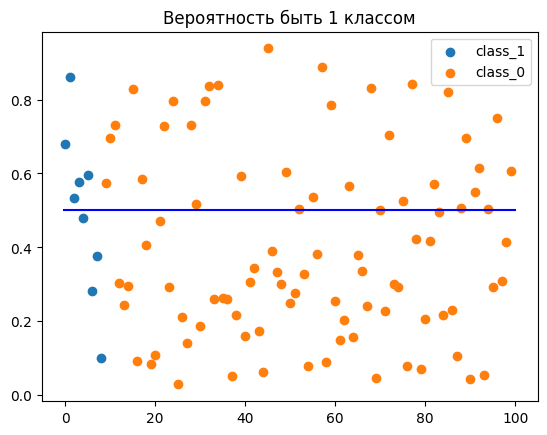

In [ ]:
threshold = 0.5
class_1 = y_prob_lr[y_test == 1]
class_0 = y_prob_lr[y_test == 0]

plt.scatter(np.arange(len(class_1)), class_1, label='class_1')
plt.scatter(np.arange(len(class_1), len(class_1)+len(class_0)), class_0, label='class_0')
plt.plot([-0.2, len(y_prob_lr)], [threshold, threshold], c='b')
plt.title('Вероятность быть 1 классом')
plt.legend();

In [ ]:
cm1 = confusion_matrix(y_test, y_pred_lr)
print(cm1)


[[58 33]
 [ 4  5]]


In [ ]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.94      0.64      0.76        91
           1       0.13      0.56      0.21         9

    accuracy                           0.63       100
   macro avg       0.53      0.60      0.49       100
weighted avg       0.86      0.63      0.71       100



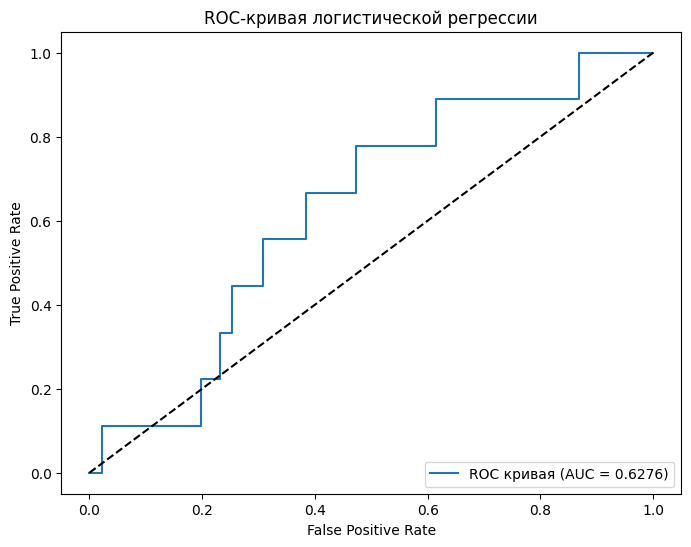

In [ ]:
roc_auc = roc_auc_score(y_test, y_prob_lr)

fpr, tpr, thresholds = roc_curve(y_test, y_prob_lr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC кривая (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая логистической регрессии')
plt.legend(loc='lower right')
plt.show()


### 4.2 SVM

In [ ]:
svc=SVC(probability=True, class_weight='balanced')

svc.fit(X_train,y_train)

y_pred_svm = svc.predict(X_test)
y_prob_svm = svc.predict_proba(X_test)[:, 1]
print('Model accuracy score with default hyperparameters: {0:0.4f}'. format(accuracy_score(y_test, y_pred)))

Model accuracy score with default hyperparameters: 0.8800


In [ ]:
y_pred_svm

array([0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1])

In [ ]:
y_prob_svm

array([0.03833934, 0.08045734, 0.08620703, 0.01887602, 0.00316801,
       0.05960228, 0.781039  , 0.0135697 , 0.02324362, 0.07008041,
       0.00146742, 0.00558844, 0.01421205, 0.03093168, 0.03084052,
       0.53624125, 0.54384776, 0.69899325, 0.00208625, 0.00186981,
       0.00292095, 0.0607673 , 0.06160506, 0.00133556, 0.33423645,
       0.60024318, 0.02482446, 0.1828276 , 0.15941744, 0.01742873,
       0.0075081 , 0.00133932, 0.0291033 , 0.13979979, 0.01217843,
       0.02631644, 0.06000675, 0.01449441, 0.00201114, 0.05995579,
       0.06914083, 0.00333835, 0.0063996 , 0.02007014, 0.01003384,
       0.00679884, 0.09010845, 0.36683187, 0.00376571, 0.00479615,
       0.03774054, 0.02476935, 0.24038158, 0.41090824, 0.00241239,
       0.03691156, 0.00811762, 0.0047195 , 0.04895194, 0.02310058,
       0.0059667 , 0.02659715, 0.21332241, 0.21560533, 0.06028684,
       0.210779  , 0.02949537, 0.06315776, 0.01530638, 0.02093123,
       0.02793909, 0.02413645, 0.01514797, 0.34821712, 0.01362

In [ ]:
cm2 = confusion_matrix(y_test, y_pred_svm)
print(cm2)

[[79 12]
 [ 3  6]]


In [ ]:
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.96      0.87      0.91        91
           1       0.33      0.67      0.44         9

    accuracy                           0.85       100
   macro avg       0.65      0.77      0.68       100
weighted avg       0.91      0.85      0.87       100



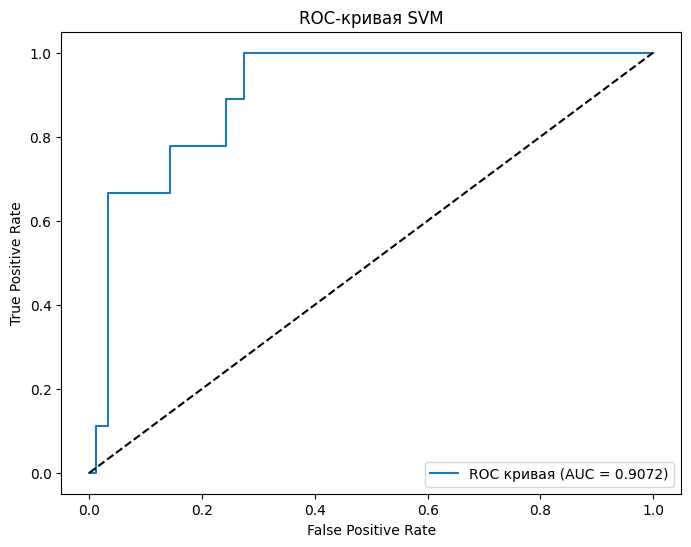

In [ ]:
roc_auc = roc_auc_score(y_test, y_prob_svm)

fpr, tpr, thresholds = roc_curve(y_test, y_prob_svm)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC кривая (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая SVM')
plt.legend(loc='lower right')
plt.show()


### 4.3 CART

In [ ]:
cart = DecisionTreeClassifier(max_depth=5, random_state=42)
cart.fit(X_train, y_train)
y_pred_cart = cart.predict(X_test)
y_prob_cart = cart.predict_proba(X_test)[:, 1]


In [ ]:
y_pred_cart

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1])

In [ ]:
y_prob_cart

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.03846154, 0.        , 0.03846154, 0.        ,
       0.        , 0.        , 0.61016949, 0.        , 0.        ,
       0.61016949, 0.61016949, 0.61016949, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.03846154,
       0.61016949, 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.03846154,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.61016949, 0.        , 0.        ,
       0.03846154, 0.        , 0.61016949, 0.        , 0.        ,
       0.03846154, 0.        , 0.        , 0.61016949, 0.        ,
       0.        , 0.        , 0.        , 0.61016949, 0.        ,
       0.        , 0.        , 0.03846154, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.61016949, 0.     

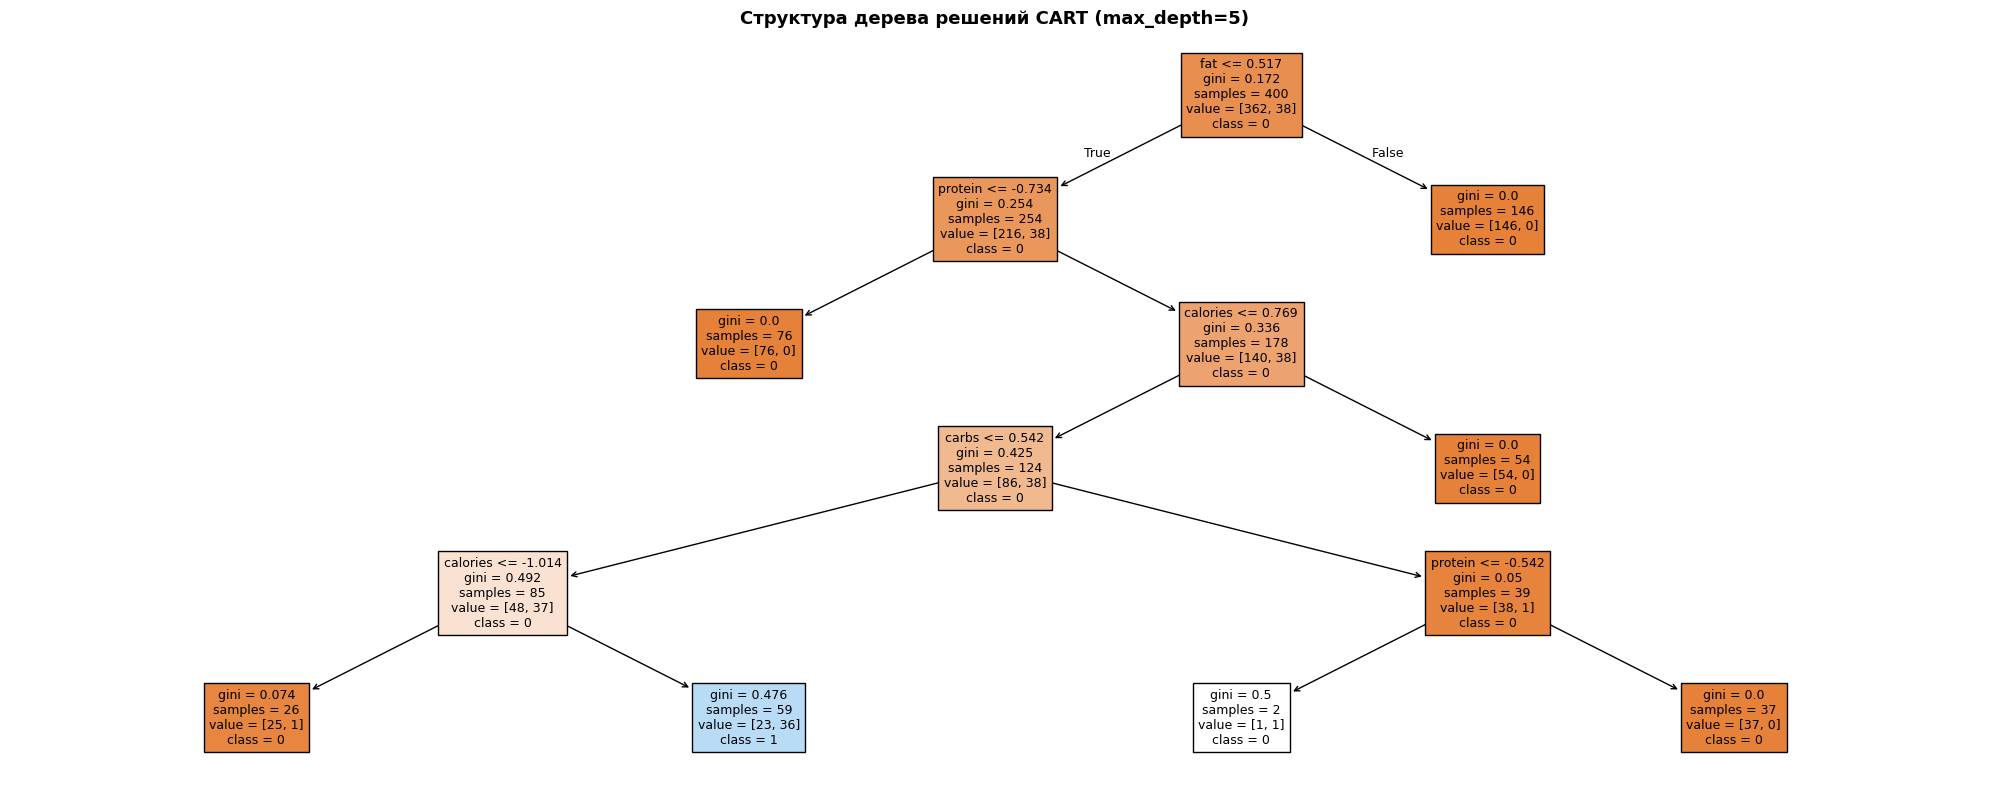

In [ ]:
plt.figure(figsize=(20, 8))
plot_tree(cart, feature_names=features,
          class_names=['0', '1'],
          filled=True, fontsize=9)
plt.title('Структура дерева решений CART (max_depth=5)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
cm3 = confusion_matrix(y_test, y_pred_cart)
print(cm3)

[[82  9]
 [ 3  6]]


In [ ]:
print(classification_report(y_test, y_pred_cart))

              precision    recall  f1-score   support

           0       0.96      0.90      0.93        91
           1       0.40      0.67      0.50         9

    accuracy                           0.88       100
   macro avg       0.68      0.78      0.72       100
weighted avg       0.91      0.88      0.89       100



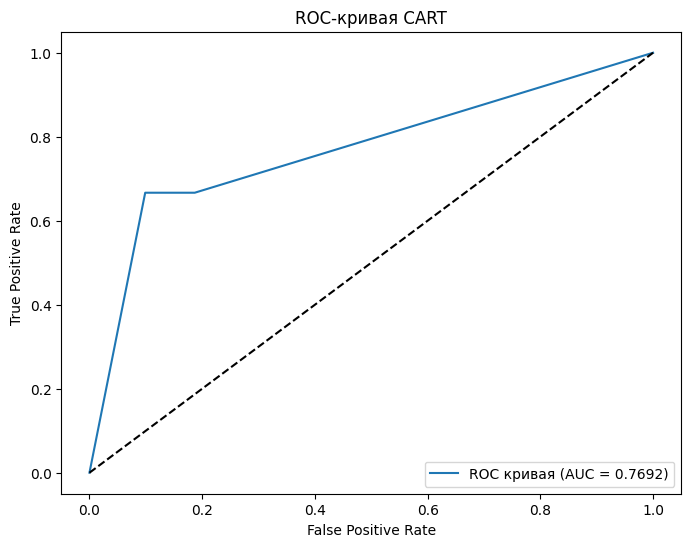

In [ ]:
roc_auc = roc_auc_score(y_test, y_prob_cart)

fpr, tpr, thresholds = roc_curve(y_test, y_prob_cart)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC кривая (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая CART')
plt.legend(loc='lower right')
plt.show()


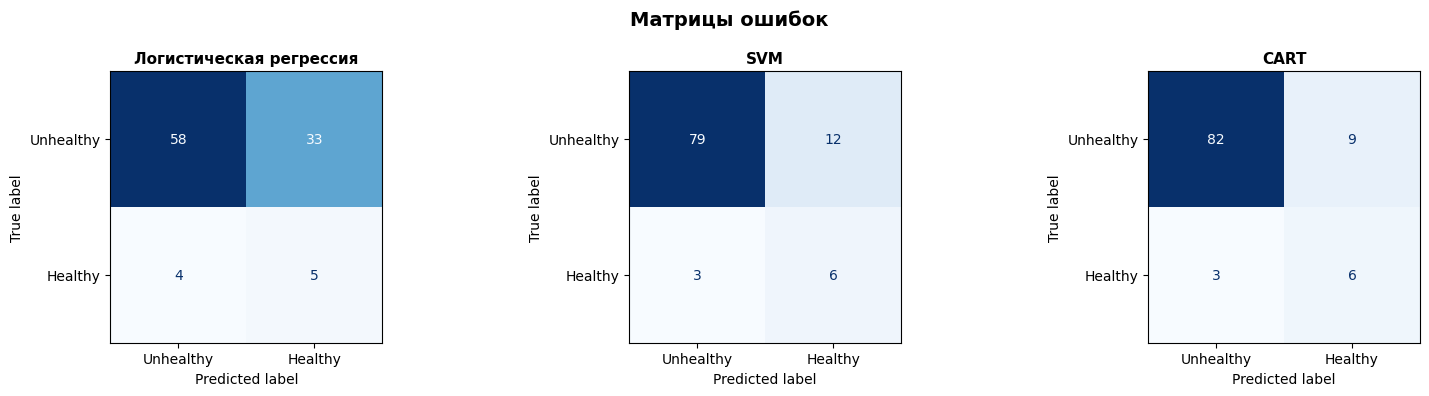

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

models_info = [
    ('Логистическая регрессия', y_pred_lr),
    ('SVM', y_pred_svm),
    ('CART', y_pred_cart),
]

for ax, (name, y_pred) in zip(axes, models_info):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Unhealthy', 'Healthy'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=11, fontweight='bold')

plt.suptitle('Матрицы ошибок', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

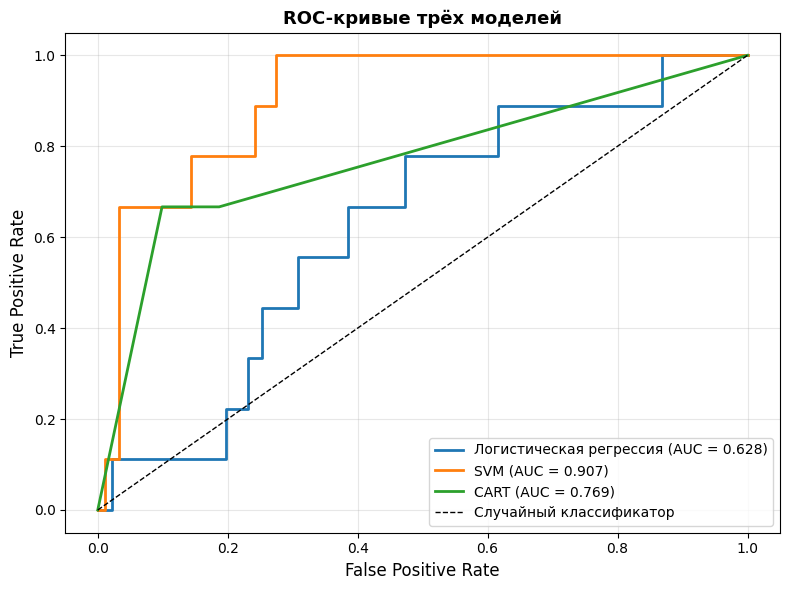

In [ ]:
plt.figure(figsize=(8, 6))

for name, y_prob in [
    ('Логистическая регрессия', y_prob_lr),
    ('SVM', y_prob_svm),
    ('CART', y_prob_cart),
]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Случайный классификатор')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC-кривые трёх моделей', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()